In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
import matplotlib.colors as mcolors
import numpy as np
import numpy.ma as ma
import pandas as pd

from km5c.gridding import connect_atlantic, create_mesh
from km5c.masks import apply_atlantic_mask_3d, apply_mask
from km5c.plotting import shade_below_bathymetry, tempequatorplot, temperatureadjustedplot
from km5c.transects import extract_transect_section_lon_band_mean, project_points_to_transect
from km5c.paths import FIG_DIR, HADCM3_BASIN_PATH
from km5c.models import load_hadcm3, load_icesm12, load_icesm13
from km5c.proxies import comparison_tables

hadcm3 = load_hadcm3()
hadcm3_Plio_d18O = hadcm3.Plio_d18O
hadcm3_Plio_depth = hadcm3.Plio_depth
hadcm3_Plio_lat = hadcm3.Plio_lat
hadcm3_Plio_lon = hadcm3.Plio_lon
hadcm3_Plio_temp = hadcm3.Plio_temp

icesm12 = load_icesm12()
Plio_d18O = icesm12.Plio_d18O
Plio_depth = icesm12.Plio_depth
Plio_lat = icesm12.Plio_lat
Plio_lon = icesm12.Plio_lon
Plio_temp = icesm12.Plio_temp

icesm13 = load_icesm13()
icesm13_Plio_d18O = icesm13.Plio_d18O
icesm13_Plio_depth = icesm13.Plio_depth
icesm13_Plio_lat = icesm13.Plio_lat
icesm13_Plio_lon = icesm13.Plio_lon
icesm13_Plio_temp = icesm13.Plio_temp

proxy = comparison_tables()
PLIOMIP2_d18O_comparison_table = proxy.PLIOMIP2_d18O_comparison_table

(1, 60, 180, 360)
(60, 180, 360)


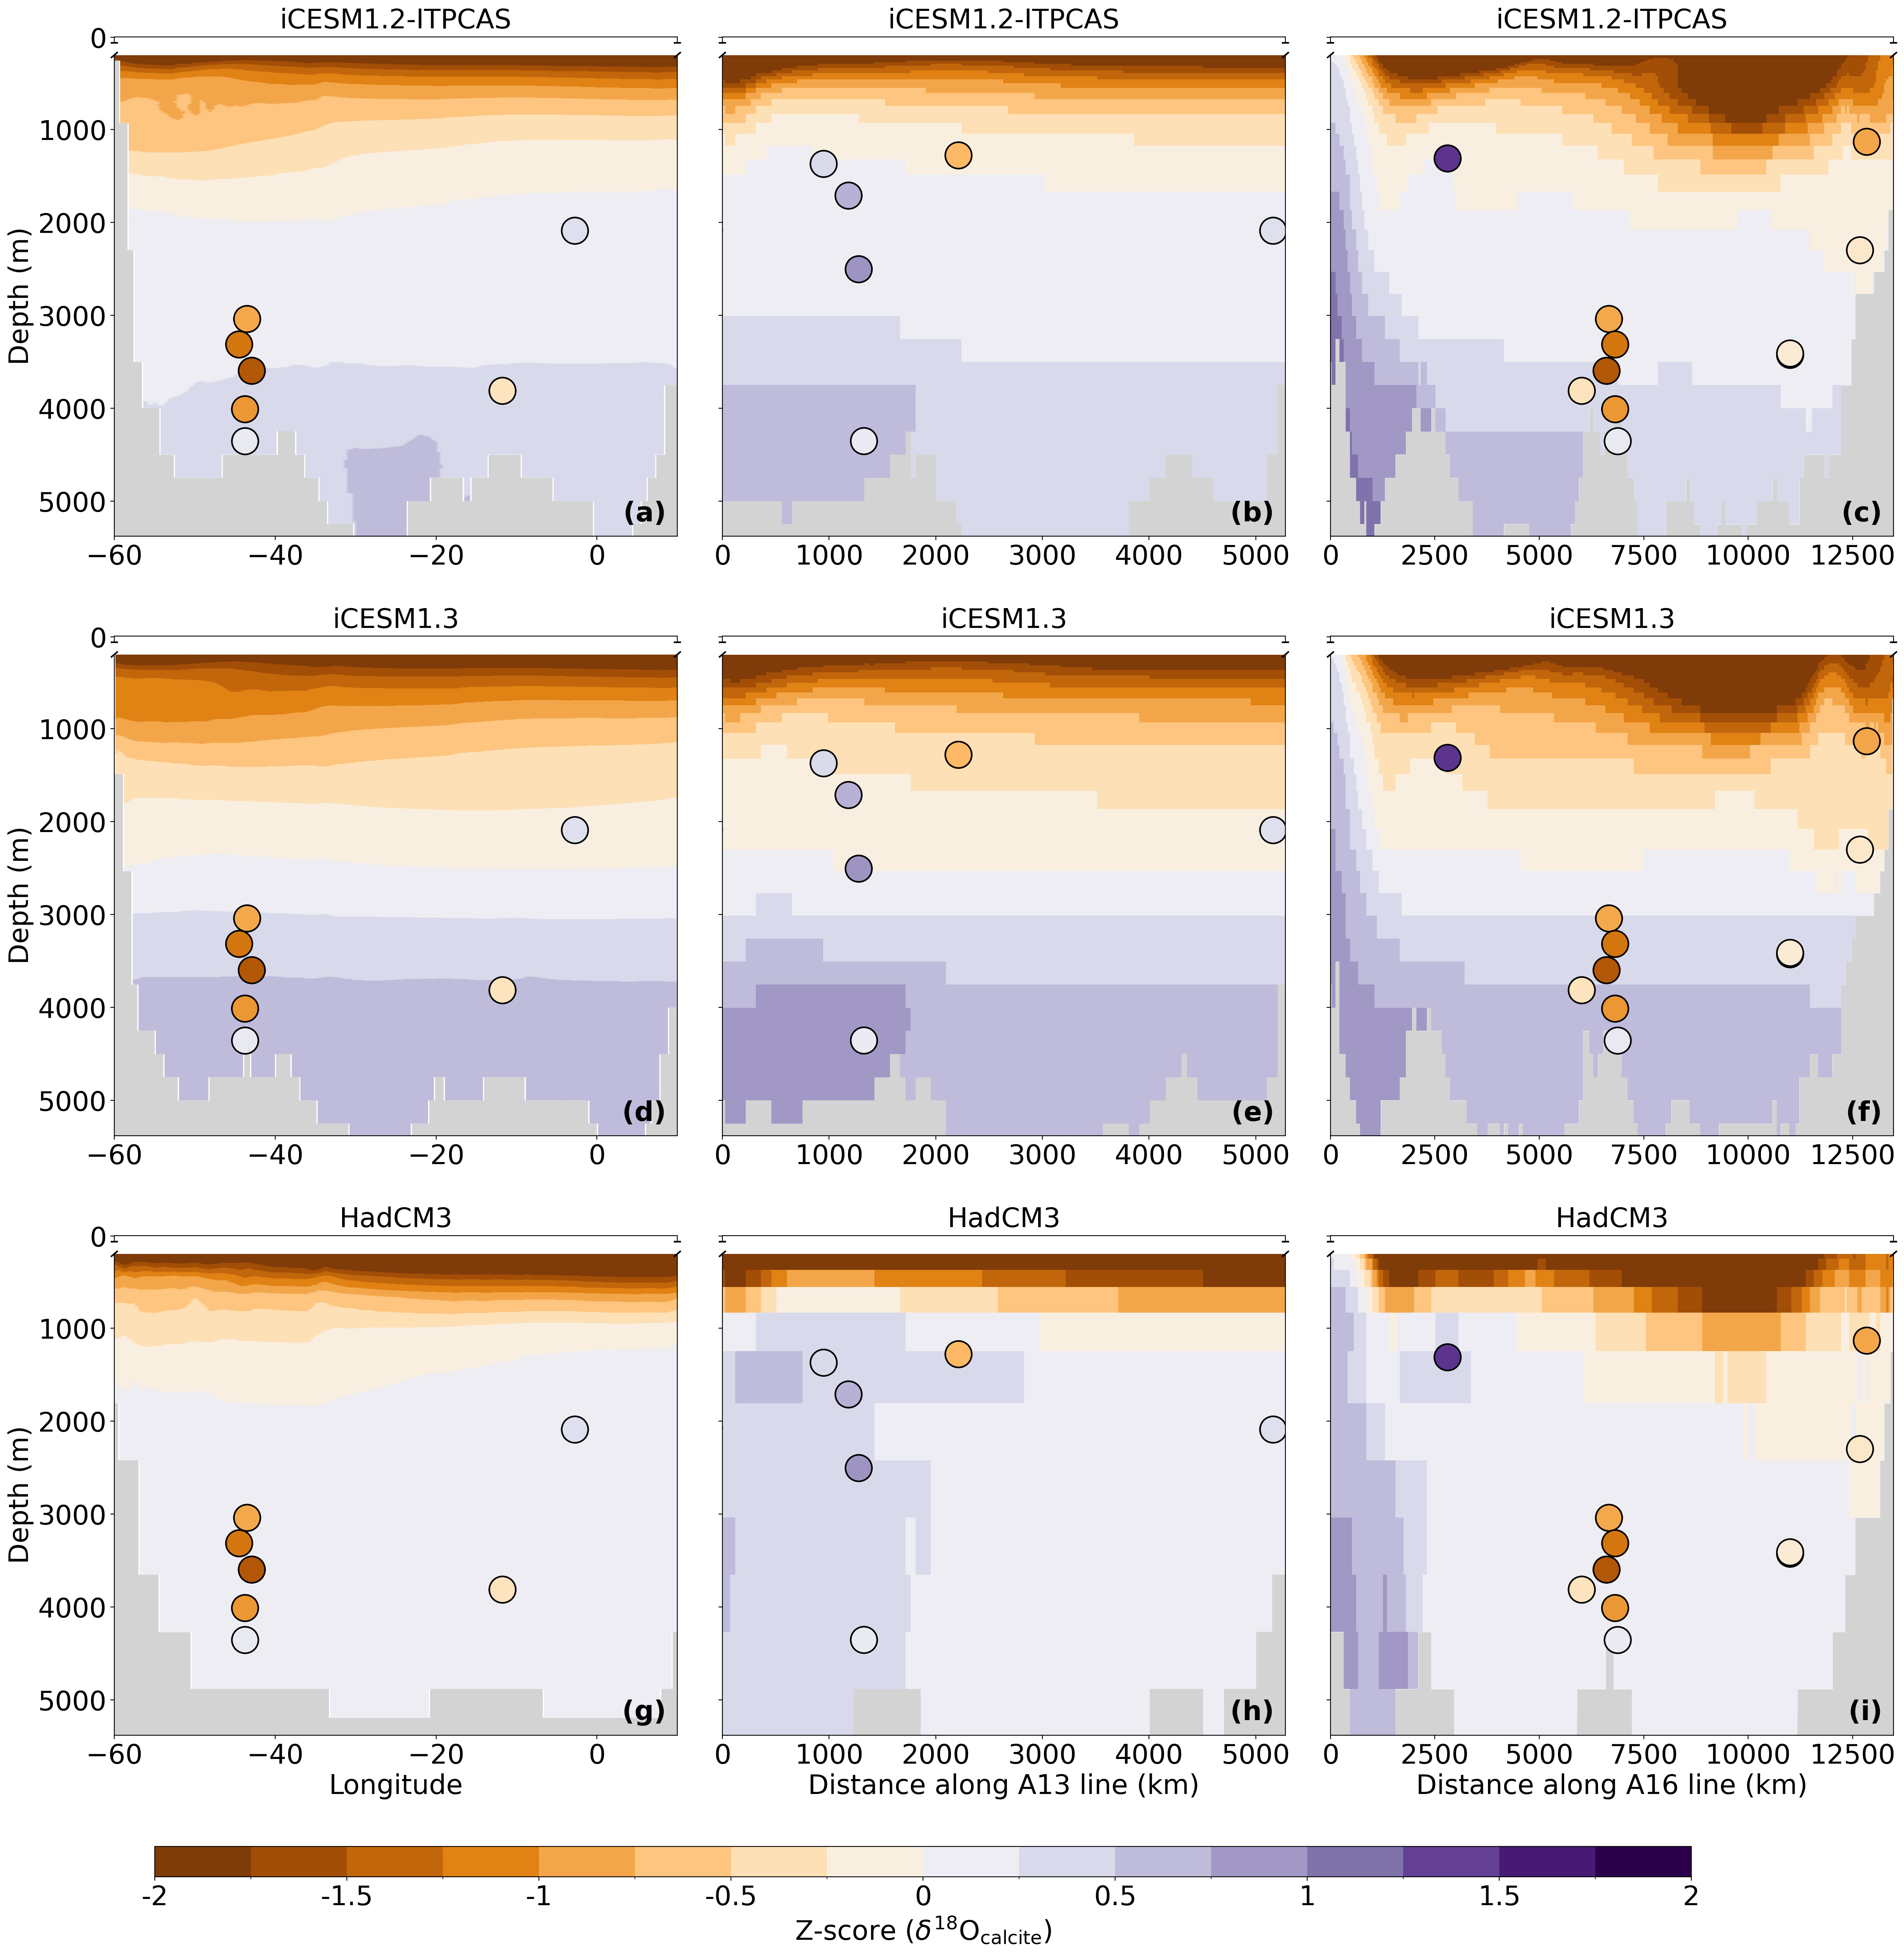

In [2]:
import re
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()
mpl.rcParams.update({
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
})

# Transect geometry (d13C.ipynb)
A13_line_lon = [10, 10, 9, 5, 5, -1]
A13_line_lat = [-40, -30, -25.3, -20, -5, 4.5]

A16_line_lon = [-36, -25, -25, -29, -29, -20, -20]
A16_line_lat = [-54, -35, 0, 11, 20, 36.5, 63.2]

box_lat_min, box_lat_max = -10.5, 10.5
box_lon_min, box_lon_max = -60, 10

color_bins = [-2, -1.75, -1.5, -1.25, -1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2]
num_colors = len(color_bins) - 1
colors = plt.cm.PuOr(np.linspace(0, 1, num_colors))
cmap = mcolors.ListedColormap(colors)
cmap.set_bad(color="white", alpha=0)
norm = mcolors.BoundaryNorm(boundaries=color_bins, ncolors=num_colors)

points_df = PLIOMIP2_d18O_comparison_table.copy()
points_df = points_df[points_df["Site name"].astype(str).str.lower() != "average"].copy()
for column in ["Longitude", "Latitude", "Water depth (m)", "PLIOMIP2 d18O"]:
    points_df[column] = pd.to_numeric(points_df[column], errors="coerce")
points_df = points_df.dropna(subset=["Longitude", "Latitude", "Water depth (m)", "PLIOMIP2 d18O"]).copy()
points_df["Longitude_wrapped"] = ((points_df["Longitude"] + 180) % 360) - 180

points_d18O = points_df["PLIOMIP2 d18O"]
points_df_mean = points_d18O.mean()
points_df_std = points_d18O.std()

# --- Basin masks (HadCM3) ---
BASIN_HADCM3_PATH = HADCM3_BASIN_PATH
ATLANTIC_BASIN_INDEX = 3
hadcm3_lat = 144
hadcm3_lon = 288

with open(BASIN_HADCM3_PATH, "r", encoding="utf-8", errors="ignore") as f:
    basin_lines = f.readlines()

basin_row_data = []
for line in basin_lines:
    stripped = line.strip()
    if not stripped or stripped.startswith("C"):
        continue
    if not re.match(r"^\d+", stripped):
        continue
    nums = [int(x) for x in re.findall(r"-?\d+", stripped)]
    if len(nums) >= 17:
        basin_row_data.append((nums[0], nums[1:17]))

n_rows_file = max(r for r, _ in basin_row_data)
mask_file = np.zeros((n_rows_file, 288), dtype=bool)
for row_id, vals in basin_row_data:
    r = row_id - 1
    base = (ATLANTIC_BASIN_INDEX - 1) * 4
    segs = vals[base:base + 4]
    for s, e in [(segs[0], segs[1]), (segs[2], segs[3])]:
        if s <= 0 or e <= 0:
            continue
        s0, e0 = max(0, s - 1), min(287, e - 1)
        if e0 >= s0:
            mask_file[r, s0:e0 + 1] = True
        else:
            mask_file[r, s0:] = True
            mask_file[r, :e0 + 1] = True

mask_hadcm3 = mask_file[np.round(np.linspace(0, n_rows_file - 1, hadcm3_lat)).astype(int), :288]


def mask_invalid(data, floor=-10.0):
    masked = ma.masked_invalid(ma.asarray(data, dtype=float))
    if floor is not None:
        masked = ma.masked_where(masked < floor, masked)
    return masked


def model_ref_stats(lat, lon, depth, d18O, temp, **kwargs):
    ref_plot, _, _ = temperatureadjustedplot(
        lat, lon, depth, d18O, temp, normalise=False, **kwargs,
    )
    return np.nanmean(ref_plot), np.nanstd(ref_plot)


def zscore_transect_panels(equator_data, a13_data, a16_data, ref_mean, ref_std):
    def z(data):
        return (mask_invalid(data) - ref_mean) / ref_std

    return z(equator_data), z(a13_data), z(a16_data)


def calcite_transect_section(d18O, temp, lat, lon, depth, line_lon, line_lat, mesh=False, mask=None, mask_lat=None, mask_lon=None):
    if mesh:
        latmesh, lonmesh = lat, lon
    else:
        latmesh, lonmesh = create_mesh(lat, lon)

    if mask is not None:
        d18O = apply_mask(d18O, latmesh, lonmesh, mask, mask_lat, mask_lon)
        temp = apply_mask(temp, latmesh, lonmesh, mask, mask_lat, mask_lon)
    else:
        connected_lon = connect_atlantic(lonmesh)
        d18O = apply_atlantic_mask_3d(d18O, latmesh, connected_lon, depth)
        temp = apply_atlantic_mask_3d(temp, latmesh, connected_lon, depth)
    d18O_sec = extract_transect_section_lon_band_mean(
        d18O, lat, lon, depth, line_lon, line_lat, spacing_km=50, mesh=mesh,
    )
    temp_sec = extract_transect_section_lon_band_mean(
        temp, lat, lon, depth, line_lon, line_lat, spacing_km=50, mesh=mesh,
    )
    section = (-0.224 * temp_sec["section"]) + 3.26 + d18O_sec["section"]
    section = mask_invalid(section)
    section[d18O_sec["depth"] < 200, :] = ma.masked
    return section, np.asarray(d18O_sec["distance_km"], dtype=float), d18O_sec["depth"]


# =============================================================================
# ROW 0 — iCESM1.2-ITPCAS (Plio_*)
# =============================================================================
icesm_equator_raw, icesm_equator_lon, icesm_equator_depth = tempequatorplot(
    Plio_lat, Plio_lon, Plio_depth, Plio_d18O, Plio_temp,
    latrange=[box_lat_min, box_lat_max],
    trimtop=True, normalise=False, top=200,
    mesh=False,
)

icesm_a13_raw, icesm_a13_x, icesm_a13_depth = calcite_transect_section(
    Plio_d18O, Plio_temp, Plio_lat, Plio_lon, Plio_depth,
    A13_line_lon, A13_line_lat, mesh=False,
)

icesm_a16_raw, icesm_a16_x, icesm_a16_depth = calcite_transect_section(
    Plio_d18O, Plio_temp, Plio_lat, Plio_lon, Plio_depth,
    A16_line_lon, A16_line_lat, mesh=False,
)

icesm_ref_mean, icesm_ref_std = model_ref_stats(
    Plio_lat, Plio_lon, Plio_depth, Plio_d18O, Plio_temp,
    mesh=False,
)
icesm_equator, icesm_a13, icesm_a16 = zscore_transect_panels(
    icesm_equator_raw, icesm_a13_raw, icesm_a16_raw, icesm_ref_mean, icesm_ref_std,
)

# =============================================================================
# ROW 1 — iCESM1.3 (icesm13_Plio_*)
# =============================================================================
cesm_equator_raw, cesm_equator_lon, cesm_equator_depth = tempequatorplot(
    icesm13_Plio_lat, icesm13_Plio_lon, icesm13_Plio_depth, icesm13_Plio_d18O, icesm13_Plio_temp,
    latrange=[box_lat_min, box_lat_max],
    trimtop=True, normalise=False, top=200,
    mesh=False,
)

cesm_a13_raw, cesm_a13_x, cesm_a13_depth = calcite_transect_section(
    icesm13_Plio_d18O, icesm13_Plio_temp, icesm13_Plio_lat, icesm13_Plio_lon, icesm13_Plio_depth,
    A13_line_lon, A13_line_lat, mesh=False,
)

cesm_a16_raw, cesm_a16_x, cesm_a16_depth = calcite_transect_section(
    icesm13_Plio_d18O, icesm13_Plio_temp, icesm13_Plio_lat, icesm13_Plio_lon, icesm13_Plio_depth,
    A16_line_lon, A16_line_lat, mesh=False,
)

cesm_ref_mean, cesm_ref_std = model_ref_stats(
    icesm13_Plio_lat, icesm13_Plio_lon, icesm13_Plio_depth, icesm13_Plio_d18O, icesm13_Plio_temp,
    mesh=False,
)
cesm_equator, cesm_a13, cesm_a16 = zscore_transect_panels(
    cesm_equator_raw, cesm_a13_raw, cesm_a16_raw, cesm_ref_mean, cesm_ref_std,
)

# =============================================================================
# ROW 2 — HadCM3 (hadcm3_Plio_*)
# =============================================================================
hadcm3_equator_raw, hadcm3_equator_lon, hadcm3_equator_depth = tempequatorplot(
    hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_Plio_depth, hadcm3_Plio_d18O, hadcm3_Plio_temp,
    latrange=[box_lat_min, box_lat_max],
    trimtop=True, normalise=False, top=200,
    mesh=False,
    
)

hadcm3_a13_raw, hadcm3_a13_x, hadcm3_a13_depth = calcite_transect_section(
    hadcm3_Plio_d18O, hadcm3_Plio_temp, hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_Plio_depth,
    A13_line_lon, A13_line_lat, mesh=False,
)

hadcm3_a16_raw, hadcm3_a16_x, hadcm3_a16_depth = calcite_transect_section(
    hadcm3_Plio_d18O, hadcm3_Plio_temp, hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_Plio_depth,
    A16_line_lon, A16_line_lat, mesh=False,
)

hadcm3_ref_mean, hadcm3_ref_std = model_ref_stats(
    hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_Plio_depth, hadcm3_Plio_d18O, hadcm3_Plio_temp,
    mesh=False,
)
hadcm3_equator, hadcm3_a13, hadcm3_a16 = zscore_transect_panels(
    hadcm3_equator_raw, hadcm3_a13_raw, hadcm3_a16_raw, hadcm3_ref_mean, hadcm3_ref_std,
)

# =============================================================================
# PLIOMIP2 scatter positions
# =============================================================================
equator_points = points_df[
    points_df["Latitude"].between(box_lat_min, box_lat_max)
    & points_df["Longitude_wrapped"].between(box_lon_min, box_lon_max)
    & points_df["Water depth (m)"].between(200, 5380)
].copy()

A13_points = project_points_to_transect(
    points_df, A13_line_lon, A13_line_lat, "PLIOMIP2 d18O", longitude_window_deg=10.0,
)
A13_points = A13_points[A13_points["depth_m"].between(200, 5380)].copy()

A16_points = project_points_to_transect(
    points_df, A16_line_lon, A16_line_lat, "PLIOMIP2 d18O", longitude_window_deg=10.0,
)
A16_points = A16_points[A16_points["depth_m"].between(200, 5380)].copy()


def draw_panel(fig, outer_grid, row, col, x, depth, data, xlim, shading,
               scatter_x, scatter_y, scatter_v, scatter_mean, scatter_std,
               xlabel=None, ylabel=False, panel_label="", model_title=None):
    inner = outer_grid[row, col].subgridspec(2, 1, height_ratios=[1, 80], hspace=0.05)
    ax1 = fig.add_subplot(inner[0, 0])
    ax2 = fig.add_subplot(inner[1, 0], sharex=ax1)

    shade_below_bathymetry(ax1, x, depth, data)
    ax1.pcolormesh(x, depth, data, cmap=cmap, norm=norm, shading=shading)
    if model_title is not None:
        ax1.set_title(model_title, fontsize=25, pad=8)
    ax1.set_ylim(-1, 10)
    ax1.set_xlim(xlim)
    ax1.set_yticks([0])
    ax1.tick_params(bottom=False, labelbottom=False)
    if col > 0:
        ax1.tick_params(labelleft=False)

    shade_below_bathymetry(ax2, x, depth, data)
    pc = ax2.pcolormesh(x, depth, data, cmap=cmap, norm=norm, shading=shading)
    ax2.set_ylim(200, 5380)
    ax2.set_xlim(xlim)
    if xlabel is not None:
        ax2.set_xlabel(xlabel)
    if ylabel:
        ax2.set_ylabel("Depth (m)")
    else:
        ax2.tick_params(labelleft=False)

    ax1.invert_yaxis()
    ax2.invert_yaxis()
    ax1.spines["bottom"].set_visible(False)
    ax2.spines["top"].set_visible(False)

    if len(scatter_x) > 0:
        scatter_c = (pd.to_numeric(scatter_v, errors="coerce") - scatter_mean) / scatter_std
        ax2.scatter(
            scatter_x, scatter_y, c=scatter_c,
            cmap="PuOr", s=600, vmin=-2, vmax=2,
            marker="o",
            edgecolors="black",
            linewidths=1.5,
        )

    d = 0.005
    kwargs = dict(transform=ax1.transAxes, color="k", clip_on=False)
    ax1.plot((-d, +d), (-d, +d), **kwargs)
    ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
    kwargs.update(transform=ax2.transAxes)
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
    ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

    ax2.text(0.98, 0.02, panel_label, transform=ax2.transAxes,
             ha="right", va="bottom", fontsize=25, fontweight="bold", zorder=20)
    return pc


# =============================================================================
# Figure — 3×3 grid
# =============================================================================
fig = plt.figure(figsize=(26, 26), dpi=200)
outer_grid = fig.add_gridspec(
    3, 3, hspace=0.20, wspace=0.08, left=0.10, right=0.98, top=0.97, bottom=0.13,
)

# Row 0 — iCESM1.2-ITPCAS
pc_for_cbar = draw_panel(
    fig, outer_grid, 0, 0,
    icesm_equator_lon, icesm_equator_depth, icesm_equator, (box_lon_min, box_lon_max), "gouraud",
    equator_points["Longitude_wrapped"], equator_points["Water depth (m)"], equator_points["PLIOMIP2 d18O"],
    points_df_mean, points_df_std, ylabel=True, panel_label="(a)", model_title="iCESM1.2-ITPCAS",
)
draw_panel(
    fig, outer_grid, 0, 1,
    icesm_a13_x, icesm_a13_depth, icesm_a13, (0, np.nanmax(icesm_a13_x)), "auto",
    A13_points["distance_km"], A13_points["depth_m"], A13_points["value"],
    points_df_mean, points_df_std, panel_label="(b)", model_title="iCESM1.2-ITPCAS",
)
draw_panel(
    fig, outer_grid, 0, 2,
    icesm_a16_x, icesm_a16_depth, icesm_a16, (0, np.nanmax(icesm_a16_x)), "auto",
    A16_points["distance_km"], A16_points["depth_m"], A16_points["value"],
    points_df_mean, points_df_std, panel_label="(c)", model_title="iCESM1.2-ITPCAS",
)

# Row 1 — iCESM1.3
draw_panel(
    fig, outer_grid, 1, 0,
    cesm_equator_lon, cesm_equator_depth, cesm_equator, (box_lon_min, box_lon_max), "gouraud",
    equator_points["Longitude_wrapped"], equator_points["Water depth (m)"], equator_points["PLIOMIP2 d18O"],
    points_df_mean, points_df_std, ylabel=True, panel_label="(d)", model_title="iCESM1.3",
)
draw_panel(
    fig, outer_grid, 1, 1,
    cesm_a13_x, cesm_a13_depth, cesm_a13, (0, np.nanmax(cesm_a13_x)), "auto",
    A13_points["distance_km"], A13_points["depth_m"], A13_points["value"],
    points_df_mean, points_df_std, panel_label="(e)", model_title="iCESM1.3",
)
draw_panel(
    fig, outer_grid, 1, 2,
    cesm_a16_x, cesm_a16_depth, cesm_a16, (0, np.nanmax(cesm_a16_x)), "auto",
    A16_points["distance_km"], A16_points["depth_m"], A16_points["value"],
    points_df_mean, points_df_std, panel_label="(f)", model_title="iCESM1.3",
)

# Row 2 — HadCM3
draw_panel(
    fig, outer_grid, 2, 0,
    hadcm3_equator_lon, hadcm3_equator_depth, hadcm3_equator, (box_lon_min, box_lon_max), "gouraud",
    equator_points["Longitude_wrapped"], equator_points["Water depth (m)"], equator_points["PLIOMIP2 d18O"],
    points_df_mean, points_df_std, xlabel="Longitude", ylabel=True, panel_label="(g)", model_title="HadCM3",
)
draw_panel(
    fig, outer_grid, 2, 1,
    hadcm3_a13_x, hadcm3_a13_depth, hadcm3_a13, (0, np.nanmax(hadcm3_a13_x)), "auto",
    A13_points["distance_km"], A13_points["depth_m"], A13_points["value"],
    points_df_mean, points_df_std, xlabel="Distance along A13 line (km)", panel_label="(h)", model_title="HadCM3",
)
draw_panel(
    fig, outer_grid, 2, 2,
    hadcm3_a16_x, hadcm3_a16_depth, hadcm3_a16, (0, np.nanmax(hadcm3_a16_x)), "auto",
    A16_points["distance_km"], A16_points["depth_m"], A16_points["value"],
    points_df_mean, points_df_std, xlabel="Distance along A16 line (km)", panel_label="(i)", model_title="HadCM3",
)

cbar_ax = fig.add_axes([0.12, 0.06, 0.76, 0.015])
cbar = plt.colorbar(
    pc_for_cbar, cax=cbar_ax, orientation="horizontal",
    boundaries=color_bins, ticks=color_bins[::2],
)
cbar.set_ticklabels([f"{t:g}" for t in color_bins[::2]])
cbar.set_label(r"Z-score ($\delta^{18}\mathrm{O}_{\mathrm{calcite}}$)")
fig.savefig(FIG_DIR / "d18O_transects.png", dpi=300, bbox_inches="tight")
plt.show()
